#1. Set Up Kaggle Access and Download the Dataset:
First, upload your kaggle.json credentials file to Colab, then download and unzip the dataset.

In [5]:
! pip install kaggle

!mkdir -p ~/.kaggle

from google.colab import files
files.upload()

!mv kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

!kaggle datasets download -d akashgundu/signature-verification-dataset

!unzip -q signature-verification-dataset.zip -d data


Saving kaggle.json to kaggle.json
Dataset URL: https://www.kaggle.com/datasets/akashgundu/signature-verification-dataset
License(s): unknown
signature-verification-dataset.zip: Skipping, found more recently modified local copy (use --force to force download)
replace data/extract/001/1-001_01.jpg? [y]es, [n]o, [A]ll, [N]one, [r]ename: A


#2. Create a Custom PyTorch Dataset:
Since the dataset’s structure does not directly follow the ImageFolder convention, define a custom dataset that assigns a label of 0 for genuine signatures and 1 for forged ones.

In [6]:

import os
from PIL import Image
from torch.utils.data import Dataset

class SignatureDataset(Dataset):
  def __init__(self,root_dir,transform=None):
    """
    Args:
            root_dir (string): Directory with all the dataset folders.
            transform (callable, optional): Optional transform to be applied on an image.
    """
    self.samples = []
    self.transform = transform

    # Iterate through each subdirectory (user folder or forgery folder)
    for subdir in os.listdir(root_dir):
      full_path = os.path.join(root_dir,subdir)
      if os.path.isdir(full_path):
        # Folder names ending with '_forg' are forged signatures
        label = 1 if subdir.endswith('_forg') else 0
        # Iterate through image files in the folder
        for file in os.listdir(full_path):
          if file.lower().endswith(('.png', '.jpg', '.jpeg' ,'.bmp')):
            self.samples.append((os.path.join(full_path, file), label))

  def __len__(self):
      return len(self.samples)

  def __getitem__(self,index):
      path, label = self.samples[index]
      image = Image.open(path).convert('RGB')
      if self.transform:
        image = self.transform(image)
      return image, label


#3. Define Transformations and Create DataLoaders:

Set up data transformations (with augmentation for training) and split the dataset into training and validation sets.

In [7]:
from torchvision import transforms
from torch.utils.data import DataLoader , random_split

# Define transformations for training
transform_train = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])

   ])

# Define transformations for validation (no augmentation)
transform_val = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std = [0.229, 0.224, 0.225])

   ])

# Load the full dataset (adjust the 'data' path if needed)
full_dataset = SignatureDataset(root_dir='/content/data/extract', transform=transform_train)

# Split dataset into 80% training and 20% validation
train_size = int(0.8 * len(full_dataset))
val_size = len(full_dataset) - train_size
train_dataset, val_dataset = random_split(full_dataset, [train_size, val_size])

# Update the transformation for the validation dataset
val_dataset.dataset.transform = transform_val


# Create DataLoaders for training and validation
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle =False, num_workers=2)


# 4. Configure MobileNetV2 for Signature Verification:
Load the pre-trained MobileNetV2 model and modify the final classifier layer for binary classification.

In [9]:
import torch
import torch.nn as nn
from torchvision import models

# Set up the device (GPU if available)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# Load the pre-trained MobileNetV3 Small model
model = models.mobilenet_v3_small(pretrained=True)

# Get the input features of the last linear layer in the classifier
in_features = model.classifier[-1].in_features

# Replace the last linear layer with a new layer for 2 classes
model.classifier[-1] = nn.Linear(in_features, 2)
model = model.to(device)


/usr/local/lib/python3.11/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=MobileNet_V3_Small_Weights.IMAGENET1K_V1`. You can also use `weights=MobileNet_V3_Small_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
Downloading: "https://download.pytorch.org/models/mobilenet_v3_small-047dcff4.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_small-047dcff4.pth
100%|██████████| 9.83M/9.83M [00:00<00:00, 59.5MB/s]


# 5. Train the Model:
Below is a simple training loop using CrossEntropyLoss and the Adam optimizer.

In [10]:
import time
import copy

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)
num_epochs = 40

since = time.time()

best_model_wts = copy.deepcopy(model.state_dict())
best_acc = 0.0

for epoch in range(num_epochs):
  print(f'Epoch {epoch+1}/{num_epochs}')
  print('-' * 10)

  # Each epoch has a training and a validation phase
  for phase in ['train', 'val']:
    if phase == 'train':
      model.train()   # Set model to training mode
      dataloader = train_loader
    else:
      model.eval()    # Set model to evaluation mode
      dataloader = val_loader

    running_loss = 0.0
    running_corrects = 0

    # Iterate over data.
    for inputs, labels in dataloader:
      inputs = inputs.to(device)
      labels = labels.to(device)

      optimizer.zero_grad()

      # Forward pass; track gradients only in training phase
      with torch.set_grad_enabled(phase == 'train'):
        outputs = model(inputs)
        _,preds = torch.max(outputs, 1)
        loss = criterion(outputs, labels)

        if phase == 'train':
          loss.backward()
          optimizer.step()


      running_loss += loss.item() * inputs.size(0)
      running_corrects += torch.sum(preds == labels.data)


    epoch_loss = running_loss / len(dataloader.dataset)
    epoch_acc = running_corrects.double() / len(dataloader.dataset)

    print(f'{phase} Loss: {epoch_loss:.4f} Acc: {epoch_acc:.4f}')

    # Deep copy the model if validation accuracy improves

    if  phase == 'val' and epoch_acc > best_acc :
      best_acc = epoch_acc
      best_model_wts = copy.deepcopy(model.state_dict())

  print()

time_elapsed = time.time() - since
print(f'Training complete in {time_elapsed // 60:.0f}m {time_elapsed % 60:.0f}s')
print(f'Best validation Accuracy: {best_acc:.4f}')

# Load best model weights
model.load_state_dict(best_model_wts)





Epoch 1/40
----------
train Loss: 0.6100 Acc: 0.6549
val Loss: 0.6060 Acc: 0.6582

Epoch 2/40
----------
train Loss: 0.4981 Acc: 0.7464
val Loss: 0.5380 Acc: 0.7102

Epoch 3/40
----------
train Loss: 0.4043 Acc: 0.8108
val Loss: 0.5281 Acc: 0.7375

Epoch 4/40
----------
train Loss: 0.3191 Acc: 0.8617
val Loss: 0.9313 Acc: 0.6312

Epoch 5/40
----------
train Loss: 0.2370 Acc: 0.8991
val Loss: 0.6354 Acc: 0.7242

Epoch 6/40
----------
train Loss: 0.1560 Acc: 0.9383
val Loss: 0.6896 Acc: 0.7474

Epoch 7/40
----------
train Loss: 0.1146 Acc: 0.9546
val Loss: 0.7153 Acc: 0.7608

Epoch 8/40
----------
train Loss: 0.0856 Acc: 0.9678
val Loss: 0.7709 Acc: 0.7775

Epoch 9/40
----------
train Loss: 0.0679 Acc: 0.9735
val Loss: 0.9392 Acc: 0.7515

Epoch 10/40
----------
train Loss: 0.0587 Acc: 0.9782
val Loss: 1.4344 Acc: 0.7102

Epoch 11/40
----------
train Loss: 0.0511 Acc: 0.9815
val Loss: 0.8824 Acc: 0.7761

Epoch 12/40
----------
train Loss: 0.0569 Acc: 0.9795
val Loss: 0.8826 Acc: 0.7867

E

<All keys matched successfully>

TorchScript model saved (scripted).


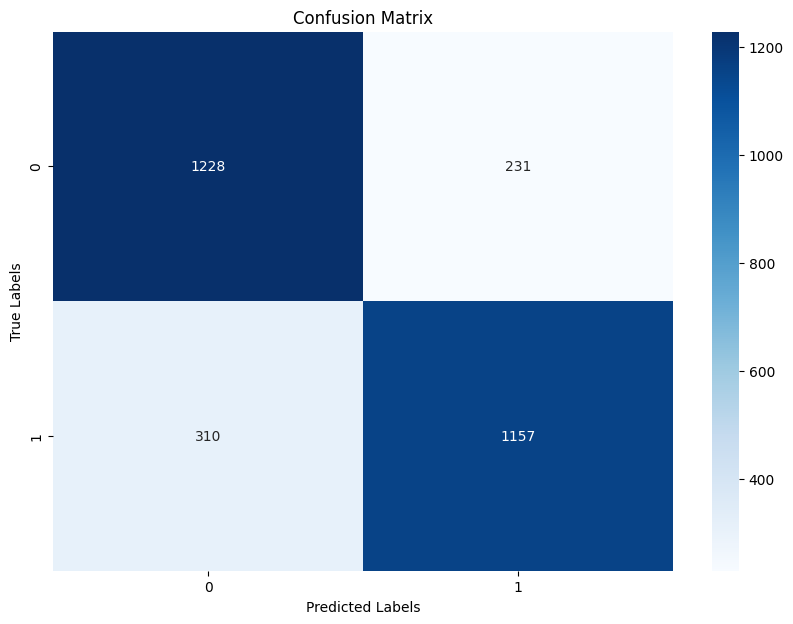

Label mapping saved to label.txt
Traced TorchScript model saved.


In [11]:
import torch
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Assume you have a test_loader (use val_loader if you don't have a separate test set)
test_loader = val_loader  # Replace with your test loader if available
num_classes = 2    # Genuine vs. forged

# -------------------------------
# Convert model to TorchScript (Script Mode)
# -------------------------------
# Convert the model to TorchScript using scripting
scripted_model = torch.jit.script(model)
scripted_model.save("model_scripted.pt")
print("TorchScript model saved (scripted).")

# -------------------------------
# Evaluate the Model and Plot Confusion Matrix
# -------------------------------
all_preds = []
all_labels = []

model.eval()   # Set model to evaluation mode
with torch.no_grad():
  for images, labels in test_loader:
    images = images.to(device)
    labels = labels.to(device)
    outputs = model(images)
    _, predicted = torch.max(outputs,1)
    all_preds.extend(predicted.cpu().numpy())
    all_labels.extend(labels.cpu().numpy())

# Compute the confusion matrix
cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(10, 7))
sns.heatmap(cm, annot=True, fmt = "d", cmap="Blues",
            xticklabels=range(num_classes), yticklabels=range(num_classes))
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()

# -------------------------------
# Save Labels Information to label.txt
# -------------------------------
label_mapping = {
    0:"Genuine",
    1:"Forged"
}

with open('label.txt','w') as label_file:
  for idx, label in label_mapping.items():
    label_file.write(f"{idx}: {label}\n")
print("Label mapping saved to label.txt")

# -------------------------------
# Convert model to TorchScript (Trace Mode)
# -------------------------------
# Move the model to CPU for tracing
device = torch.device('cpu')
model = model.to(device)
model.eval()

# Create an example input tensor for tracing (adjust dimensions as needed)
example_input = torch.rand(1, 3, 224, 224)
traced_script_module = torch.jit.trace(model, example_input)
traced_script_module.save("model_traced.pt")
print("Traced TorchScript model saved.")
